<a href="https://colab.research.google.com/github/shreeyeshapore/ML-Practicals/blob/main/Compact_Logistic_Regression_Diabetes_Experiment._Shreeyesha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression – Diabetes Prediction



**Aim:** Train Logistic Regression for binary classification and plot the sigmoid function, decision boundary and ROC curve with AUC.

Dataset: Pima Indians Diabetes (Kaggle). `Outcome`: 0 = Non-diabetic, 1 = Diabetic.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

## 1. Load and prepare the data

In [2]:
## 1. Load and prepare the data

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0             35        0  33.6   
1            1     85.0           66.0             29        0  26.6   
2            8    183.0           64.0              0        0  23.3   
3            1     89.0           66.0             23       94  28.1   
4            0    137.0           40.0             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


## 2. Train the Logistic Regression model

In [3]:
## 2. Train the Logistic Regression model

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=200, random_state=10)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8229166666666666


## 3. Sigmoid function

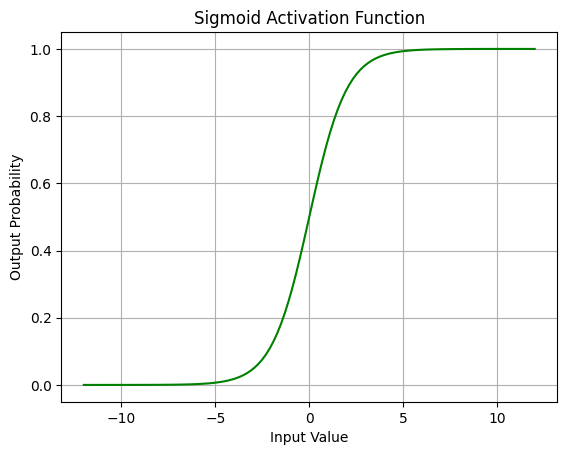

In [4]:
## 3. Sigmoid function

z = np.linspace(-12, 12, 120)
plt.plot(z, 1 / (1 + np.exp(-z)), color="green")
plt.title("Sigmoid Activation Function")
plt.xlabel("Input Value")
plt.ylabel("Output Probability")
plt.grid()
plt.show()

## 4. Decision boundary

Use Glucose and BMI to draw a simple 2D decision boundary. The main model above uses all eight features.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


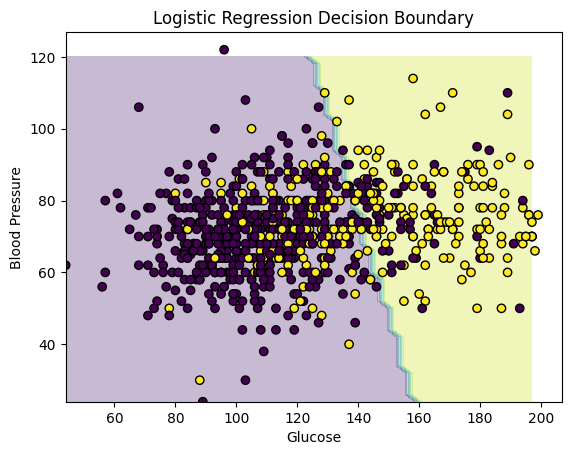

In [5]:
## 4. Decision boundary

# Use Glucose and BloodPressure to draw a simple 2D decision boundary.
# The main model above uses all eight features.

X2 = df[["Glucose", "BloodPressure"]]

a, b = np.meshgrid(
    np.arange(X2.Glucose.min(), X2.Glucose.max(), 3),
    np.arange(X2.BloodPressure.min(), X2.BloodPressure.max(), 2))

sc2 = StandardScaler()
X2_scaled = sc2.fit_transform(X2)

m2 = LogisticRegression(max_iter=200, random_state=10).fit(X2_scaled, y)

grid = sc2.transform(np.c_[a.ravel(), b.ravel()])
pred = m2.predict(grid).reshape(a.shape)

plt.contourf(a, b, pred, alpha=0.3)
plt.scatter(X2.Glucose, X2.BloodPressure, c=y, edgecolors="k")

plt.xlabel("Glucose")
plt.ylabel("Blood Pressure")
plt.title("Logistic Regression Decision Boundary")
plt.show()

## 5. ROC curve and AUC

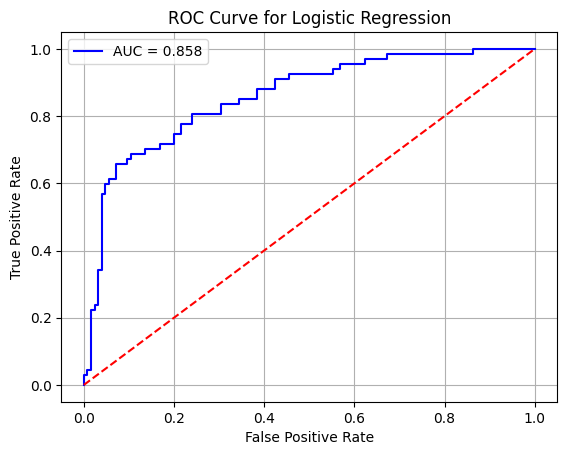

AUC Score: 0.858


In [6]:
## 5. ROC curve and AUC

prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, prob)
score = auc(fpr, tpr)

plt.plot(fpr, tpr, color="blue", label="AUC = %.3f" % score)
plt.plot([0, 1], [0, 1], "r--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("AUC Score:", round(score, 3))

## Observations
1.Logistic Regression predicts diabetic (1) or non-diabetic (0).

2.The sigmoid function converts model scores into probabilities between 0 and 1.

3.The decision boundary separates the two classes using Glucose and Blood Pressure.

4.The ROC curve compares true-positive and false-positive rates at different thresholds.

5.AUC closer to 1 indicates better separation of the two classes.

## Result
Logistic Regression was trained on the diabetes dataset. The sigmoid function, decision boundary and ROC curve were plotted, and AUC was calculated.

*This is a classroom exercise, not a medical diagnostic tool.*